In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

In [ ]:
## Setting to make numbers Easier to Read or Display
pd.options.display.float_format='{:20.2f}'.format

In [ ]:
## Show all columns on output
pd.set_option('display.max_columns',999)

In [ ]:
df=pd.read_excel(r'/content/online_retail_II.xlsx')
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.00,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.00,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.00,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.00,United Kingdom


In [ ]:
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.00,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.00,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.00,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.00,United Kingdom


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [ ]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.00,525461,525461.00,417534.00
mean,10.34,2010-06-28 11:37:36.845017856,4.69,15360.65
min,-9600.00,2009-12-01 07:45:00,-53594.36,12346.00
25%,1.00,2010-03-21 12:20:00,1.25,13983.00
50%,3.00,2010-07-06 09:51:00,2.10,15311.00
75%,10.00,2010-10-15 12:45:00,4.21,16799.00
max,19152.00,2010-12-09 20:01:00,25111.09,18287.00
std,107.42,NaN,146.13,1680.81


In [ ]:
df.describe(include="O")

,Invoice,StockCode,Description,Country
count,525461,525461,522533,525461
unique,28816,4632,4681,40
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,675,3516,3549,485852


In [ ]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [ ]:
df[df['Customer ID'].isnull()].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom
578,489525,85227,SET/6 3D KIT CARDS FOR KIDS,1,2009-12-01 11:49:00,0.85,NaN,United Kingdom
1055,489548,22271,FELTCRAFT DOLL ROSIE,1,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1056,489548,22254,FELT TOADSTOOL LARGE,12,2009-12-01 12:32:00,1.25,NaN,United Kingdom
1057,489548,22273,FELTCRAFT DOLL MOLLY,3,2009-12-01 12:32:00,2.95,NaN,United Kingdom
1058,489548,22195,LARGE HEART MEASURING SPOONS,1,2009-12-01 12:32:00,1.65,NaN,United Kingdom


In [ ]:
df[df['Quantity']<0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.00,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.00,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.00,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.00,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.00,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.00,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.00,United Kingdom


In [ ]:
df['Invoice']=df['Invoice'].astype('str')
df[df['Invoice'].str.match("^\\d{6}$")==False]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.00,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.00,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.00,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.00,Australia
...,...,...,...,...,...,...,...,...
524695,C538123,22956,36 FOIL HEART CAKE CASES,-2,2010-12-09 15:41:00,2.10,12605.00,Germany
524696,C538124,M,Manual,-4,2010-12-09 15:43:00,0.50,15329.00,United Kingdom
524697,C538124,22699,ROSES REGENCY TEACUP AND SAUCER,-1,2010-12-09 15:43:00,2.95,15329.00,United Kingdom
524698,C538124,22423,REGENCY CAKESTAND 3 TIER,-1,2010-12-09 15:43:00,12.75,15329.00,United Kingdom


In [ ]:
df['Invoice'].str.replace("[0-9]", "",regex=True).unique()

array(['', 'C', 'A'], dtype=object)

In [ ]:
df[df['Invoice'].str.startswith("A")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom


In [ ]:
df["StockCode"] = df["StockCode"].astype("str")
df[(df["StockCode"].str.match(r"^\d{5}$") == False) & (df["StockCode"].str.match(r"^\d{5}[a-zA-Z]$") == False)]['StockCode'].unique()

array(['POST', '79323LP', '15056BL', 'D', '79323GR', 'DCGS0058',
       'DCGS0068', 'DOT', '15056bl', 'M', 'DCGS0004', 'DCGS0076', 'C2',
       'BANK CHARGES', 'DCGS0003', 'TEST001', 'gift_0001_80', 'DCGS0072',
       'gift_0001_20', 'DCGS0044', 'TEST002', 'gift_0001_10',
       'gift_0001_50', 'DCGS0066N', 'gift_0001_30', 'PADS', '72024HC',
       'ADJUST', 'gift_0001_40', 'gift_0001_60', 'gift_0001_70',
       'gift_0001_90', 'DCGSSGIRL', 'DCGS0006', 'DCGS0016', 'DCGS0027',
       'DCGS0036', 'DCGS0039', 'DCGS0060', 'DCGS0056', 'DCGS0059', 'GIFT',
       'DCGSLBOY', 'm', 'DCGS0053', 'DCGS0062', 'DCGS0037', 'DCGSSBOY',
       'DCGSLGIRL', 'S', 'DCGS0069', 'DCGS0070', 'DCGS0075', 'B',
       'DCGS0041', 'ADJUST2', '47503J ', 'C3', 'SP1002', 'AMAZONFEE'],
      dtype=object)

In [ ]:
df[df['StockCode'].str.contains("POST")]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.00,12682.00,France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.00,USA
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.00,Belgium
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.00,12533.00,Germany
927,C489538,POST,POSTAGE,-1,2009-12-01 12:18:00,9.58,15796.00,United Kingdom
...,...,...,...,...,...,...,...,...
522916,537967,POST,POSTAGE,1,2010-12-09 11:31:00,18.00,12494.00,France
522930,537995,POST,POSTAGE,2,2010-12-09 11:39:00,18.00,12712.00,Germany
522974,538003,POST,POSTAGE,8,2010-12-09 12:05:00,18.00,12429.00,Denmark
523064,538008,POST,POSTAGE,5,2010-12-09 12:17:00,18.00,12683.00,France


# DATA CLEANING

In [ ]:
cleaned_df=df.copy()

In [ ]:
cleaned_df['Invoice'] = cleaned_df['Invoice'].astype('str')

mask = (
    cleaned_df['Invoice'].str.match(r"^\d{6}$") == True
)
# Keep the valid 6-digit invoices, discard cancellations/adjustments
cleaned_df = cleaned_df[mask]
cleaned_df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.00,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.00,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.00,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.00,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530.00,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530.00,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530.00,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530.00,United Kingdom


In [ ]:
cleaned_df['StockCode'] = cleaned_df['StockCode'].astype('str')

mask = (
    (cleaned_df['StockCode'].str.match(r"^\d{5}$") == True) |
    (cleaned_df["StockCode"].str.match(r"^\d{5}[a-zA-Z]+$") == True) |
    (cleaned_df["StockCode"].str.match(r"PADS$") == True)
)
cleaned_df = cleaned_df[~mask]
cleaned_df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.00,12682.00,France
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.00,USA
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.00,Belgium
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.00,12533.00,Germany
1244,489557,POST,POSTAGE,4,2009-12-01 12:52:00,18.00,12490.00,France
...,...,...,...,...,...,...,...,...
524776,538147,M,Manual,1,2010-12-09 16:11:00,15.00,13090.00,United Kingdom
524887,538148,DOT,DOTCOM POSTAGE,1,2010-12-09 16:26:00,547.32,NaN,United Kingdom
525000,538149,DOT,DOTCOM POSTAGE,1,2010-12-09 16:27:00,620.68,NaN,United Kingdom
525126,538153,DOT,DOTCOM POSTAGE,1,2010-12-09 16:31:00,822.94,NaN,United Kingdom


In [ ]:
cleaned_df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,2456.00,2456,2456.00,1358.00
mean,1.65,2010-06-22 01:41:13.949511424,177.51,13833.85
min,-4999.00,2009-12-01 09:28:00,0.00,12346.00
25%,1.00,2010-03-22 10:05:45,15.00,12583.00
50%,1.00,2010-06-24 11:47:30,19.30,12765.00
75%,2.00,2010-10-01 13:24:45,87.47,14911.00
max,1000.00,2010-12-09 16:35:00,25111.09,18287.00
std,104.35,NaN,899.45,1703.41


In [ ]:
len(cleaned_df[cleaned_df['Price']==0])

56

In [ ]:
cleaned_df=cleaned_df[cleaned_df['Price']>=0]

In [ ]:
cleaned_df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,2456.00,2456,2456.00,1358.00
mean,1.65,2010-06-22 01:41:13.949511424,177.51,13833.85
min,-4999.00,2009-12-01 09:28:00,0.00,12346.00
25%,1.00,2010-03-22 10:05:45,15.00,12583.00
50%,1.00,2010-06-24 11:47:30,19.30,12765.00
75%,2.00,2010-10-01 13:24:45,87.47,14911.00
max,1000.00,2010-12-09 16:35:00,25111.09,18287.00
std,104.35,NaN,899.45,1703.41


In [ ]:
cleaned_df['Price'].min()

0.0

In [ ]:
len(cleaned_df)/len(df)

0.0046739910288299226

Dropped about 56% of **Records**

# Feature Engineering

In [ ]:
cleaned_df['SalesLineTotal']=cleaned_df['Quantity'] * cleaned_df['Price']
cleaned_df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,SalesLineTotal
89,489439,POST,POSTAGE,3,2009-12-01 09:28:00,18.00,12682.00,France,54.00
126,489444,POST,POSTAGE,1,2009-12-01 09:55:00,141.00,12636.00,USA,141.00
173,489447,POST,POSTAGE,1,2009-12-01 10:10:00,130.00,12362.00,Belgium,130.00
625,489526,POST,POSTAGE,6,2009-12-01 11:50:00,18.00,12533.00,Germany,108.00
1244,489557,POST,POSTAGE,4,2009-12-01 12:52:00,18.00,12490.00,France,72.00
...,...,...,...,...,...,...,...,...,...
524776,538147,M,Manual,1,2010-12-09 16:11:00,15.00,13090.00,United Kingdom,15.00
524887,538148,DOT,DOTCOM POSTAGE,1,2010-12-09 16:26:00,547.32,NaN,United Kingdom,547.32
525000,538149,DOT,DOTCOM POSTAGE,1,2010-12-09 16:27:00,620.68,NaN,United Kingdom,620.68
525126,538153,DOT,DOTCOM POSTAGE,1,2010-12-09 16:31:00,822.94,NaN,United Kingdom,822.94


In [ ]:
aggregated_df= cleaned_df.groupby(by='Customer ID',as_index=False)\
.agg(
    MonetaryValue=('SalesLineTotal','sum'),
    Frequency=('Invoice','nunique'),
    LastInvoiceData=('InvoiceDate','max')
)
aggregated_df.head(5)


,Customer ID,MonetaryValue,Frequency,LastInvoiceData
0,12346.00,203.50,9,2010-01-22 13:30:00
1,12348.00,1.00,1,2010-09-27 14:59:00
2,12349.00,450.00,2,2010-10-28 08:23:00
3,12356.00,436.00,2,2010-11-11 14:23:00
4,12357.00,850.00,1,2010-11-16 14:29:00


In [ ]:
max_invoice_date=aggregated_df['LastInvoiceData'].max()
aggregated_df['Recency']=max_invoice_date-aggregated_df['LastInvoiceData']
aggregated_df.head(5)

,Customer ID,MonetaryValue,Frequency,LastInvoiceData,Recency
0,12346.00,203.50,9,2010-01-22 13:30:00,321 days 02:41:00
1,12348.00,1.00,1,2010-09-27 14:59:00,73 days 01:12:00
2,12349.00,450.00,2,2010-10-28 08:23:00,42 days 07:48:00
3,12356.00,436.00,2,2010-11-11 14:23:00,28 days 01:48:00
4,12357.00,850.00,1,2010-11-16 14:29:00,23 days 01:42:00


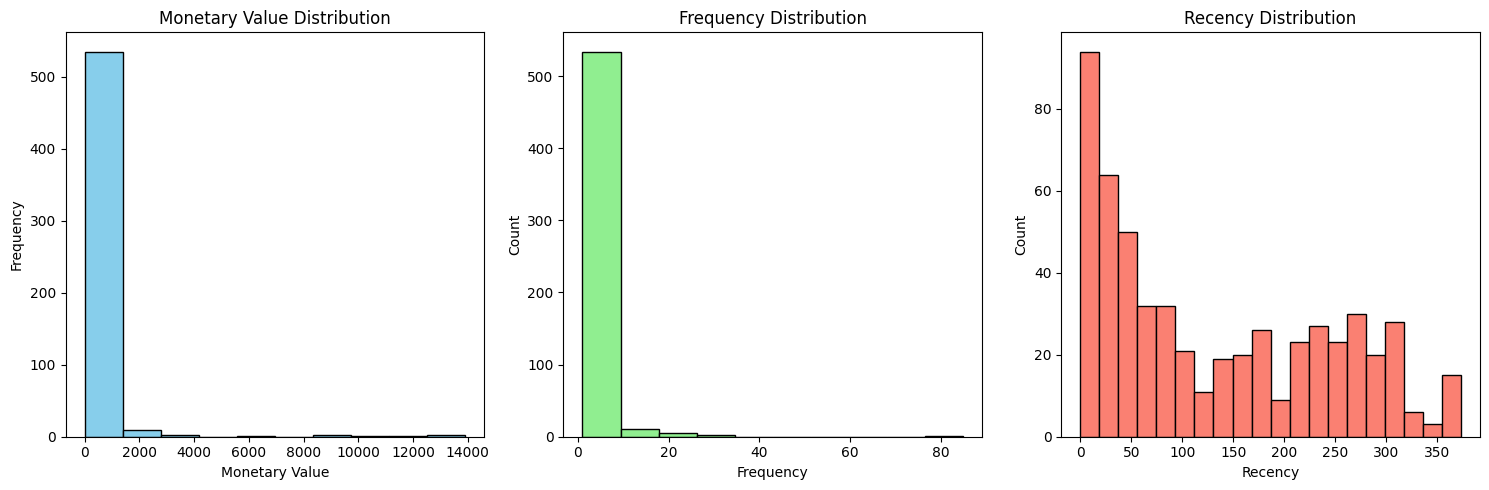

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.hist(aggregated_df['MonetaryValue'],bins=10,color='skyblue',edgecolor='black')
plt.title('Monetary Value Distribution')
plt.xlabel('Monetary Value')
plt.ylabel('Frequency')

plt.subplot(1,3,2)
plt.hist(aggregated_df['Frequency'],bins=10,color='Lightgreen',edgecolor='black')
plt.title('Frequency Distribution')
plt.xlabel('Frequency')
plt.ylabel('Count')

plt.subplot(1,3,3)
plt.hist(aggregated_df['Recency'].dt.days,bins=20,color='salmon',edgecolor='black')
plt.title('Recency Distribution')
plt.xlabel('Recency')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

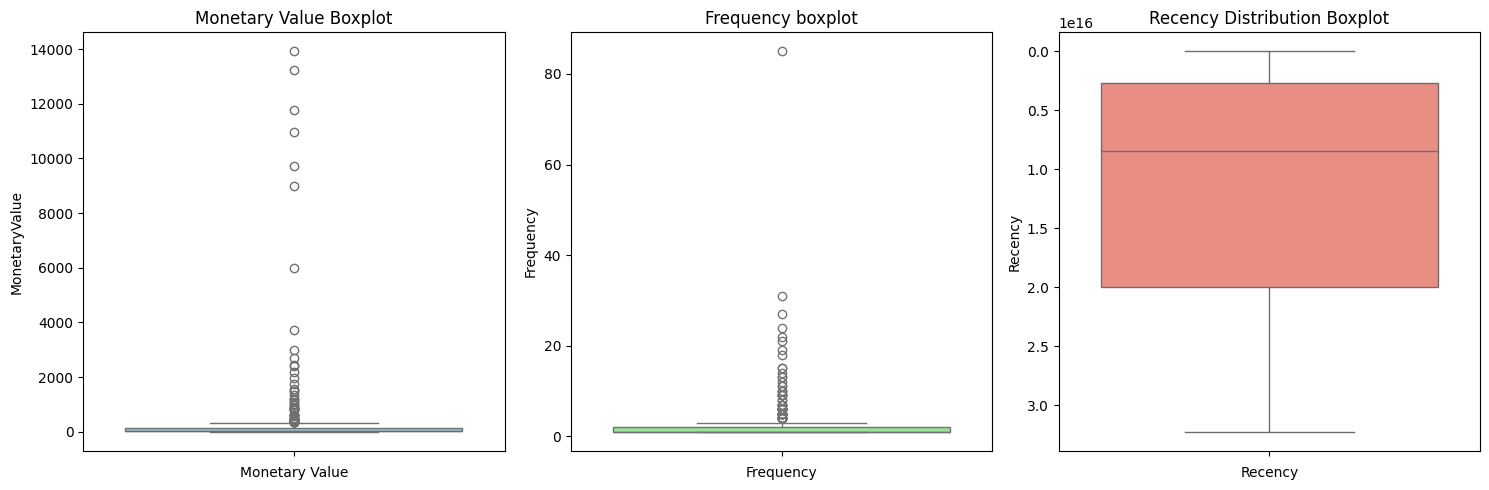

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
sns.boxplot(data=aggregated_df['MonetaryValue'],color='skyblue')
plt.title('Monetary Value Boxplot')
plt.xlabel('Monetary Value')

plt.subplot(1,3,2)
sns.boxplot(data=aggregated_df['Frequency'],color='Lightgreen')
plt.title('Frequency boxplot')
plt.xlabel('Frequency')

plt.subplot(1,3,3)
sns.boxplot(aggregated_df['Recency'],color='salmon')
plt.title('Recency Distribution Boxplot')
plt.xlabel('Recency')

plt.tight_layout()
plt.show()

In [ ]:
M_Q3=aggregated_df['MonetaryValue'].quantile(0.75)
M_Q1=aggregated_df['MonetaryValue'].quantile(0.25)
M_IQR=M_Q3-M_Q1

monetary_outliers_df=aggregated_df[(aggregated_df['MonetaryValue']<M_Q1-1.5*M_IQR) | (aggregated_df['MonetaryValue']>M_Q3+1.5*M_IQR)]
monetary_outliers_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceData,Recency
count,62.00,62.00,62.00,62,62
mean,13319.50,2049.52,8.31,2010-09-28 20:17:45.483870976,71 days 19:53:14.516129032
min,12349.00,342.80,1.00,2009-12-10 11:50:00,0 days 01:22:00
25%,12484.75,433.00,2.00,2010-09-03 10:32:15,9 days 02:24:15
50%,12681.50,834.51,5.00,2010-11-09 00:10:30,30 days 16:00:30
75%,14001.00,1536.74,9.75,2010-11-30 13:46:45,97 days 05:38:45
max,17949.00,13916.34,85.00,2010-12-09 14:49:00,364 days 04:21:00
std,1294.85,3288.77,12.15,NaN,90 days 14:37:49.619375108


In [ ]:
f_Q1=aggregated_df['Frequency'].quantile(0.25)
f_Q3=aggregated_df['Frequency'].quantile(0.75)
f_IQR=f_Q3-f_Q1

frequency_outliers_df=aggregated_df[(aggregated_df['Frequency']<f_Q1-1.5*f_IQR) | (aggregated_df['Frequency']>f_Q3+1.5*f_IQR)]
frequency_outliers_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceData,Recency
count,66.00,66.00,66.00,66,66
mean,13031.45,902.45,9.82,2010-11-04 05:27:40.000000256,35 days 10:43:20
min,12346.00,46.89,4.00,2010-01-22 13:30:00,0 days 01:22:00
25%,12523.25,200.88,5.00,2010-10-26 22:27:00,6 days 16:58:00
50%,12655.50,344.00,6.00,2010-11-23 00:42:00,16 days 15:29:00
75%,12777.75,846.75,10.00,2010-12-02 23:13:00,43 days 17:44:00
max,17448.00,11768.68,85.00,2010-12-09 14:49:00,321 days 02:41:00
std,1053.20,1872.52,11.13,NaN,52 days 02:09:43.066439281


In [ ]:
non_outliers_df=aggregated_df[(~aggregated_df.index.isin(monetary_outliers_df.index)) &(~aggregated_df.index.isin(frequency_outliers_df))]
non_outliers_df.describe()

,Customer ID,MonetaryValue,Frequency,LastInvoiceData,Recency
count,491.00,491.00,491.00,491,491
mean,14550.03,64.26,1.63,2010-07-22 00:38:30.916496640,140 days 15:32:29.083503054
min,12346.00,0.00,1.00,2009-12-01 09:55:00,0 days 00:00:00
25%,12693.50,5.97,1.00,2010-04-12 14:23:30,36 days 14:17:00
50%,14016.00,28.00,1.00,2010-08-18 10:03:00,113 days 06:08:00
75%,16329.50,94.30,2.00,2010-11-03 01:54:00,241 days 01:47:30
max,18287.00,324.00,12.00,2010-12-09 16:11:00,373 days 06:16:00
std,1973.12,80.37,1.38,NaN,110 days 13:42:09.196938400


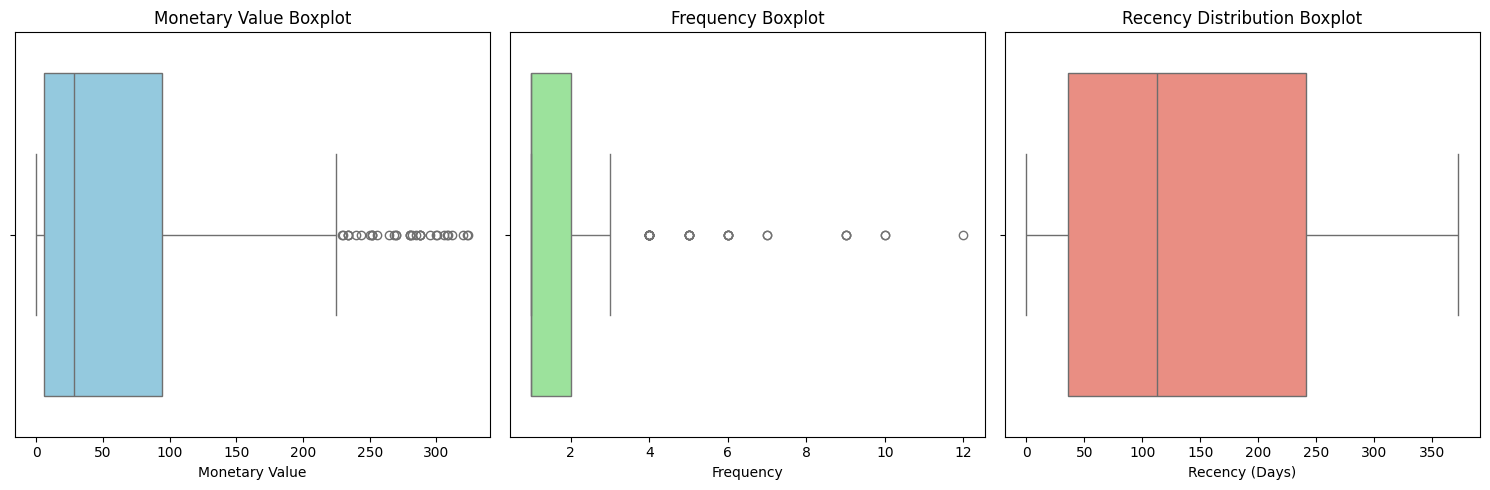

In [ ]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
sns.boxplot(data=non_outliers_df, x='MonetaryValue', color='skyblue')
plt.title('Monetary Value Boxplot')
plt.xlabel('Monetary Value')

plt.subplot(1,3,2)
sns.boxplot(data=non_outliers_df, x='Frequency', color='lightgreen')
plt.title('Frequency Boxplot')
plt.xlabel('Frequency')

plt.subplot(1,3,3)
# Convert Recency timedelta to days for plotting
sns.boxplot(x=non_outliers_df['Recency'].dt.days, color='salmon')
plt.title('Recency Distribution Boxplot')
plt.xlabel('Recency (Days)')

plt.tight_layout()
plt.show()

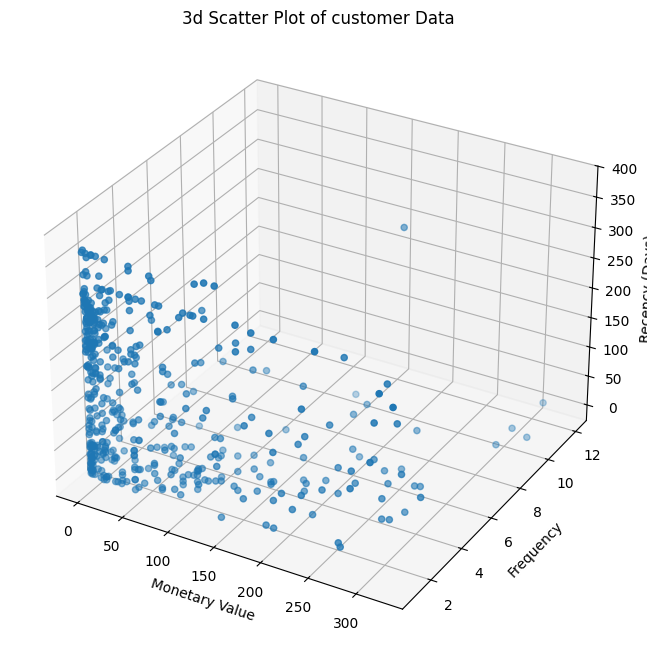

In [ ]:
fig=plt.figure(figsize=(8,8))
ax=fig.add_subplot(projection='3d')
scatter=ax.scatter(
    non_outliers_df['MonetaryValue'],
    non_outliers_df['Frequency'],
    non_outliers_df['Recency'].dt.days,
)
ax.set_xlabel('Monetary Value')
ax.set_ylabel('Frequency')
ax.set_zlabel('Recency (Days)')
ax.set_title('3d Scatter Plot of customer Data')
plt.show()

In [ ]:
scaler = StandardScaler()
# Prepare the features correctly with matched casing and converted Recency in days
features_df = non_outliers_df[['MonetaryValue', 'Frequency']].copy()
features_df['Recency_Days'] = non_outliers_df['Recency'].dt.days

scaled_data = scaler.fit_transform(features_df)
scaled_data

array([[ 1.73433078,  5.36631483,  1.63555476],
       [-0.78787413, -0.45658148, -0.6103543 ],
       [ 1.69073711, -0.45658148, -1.18088765],
       ...,
       [-0.17756282, -0.45658148,  1.40009655],
       [-0.17756282, -0.45658148,  1.9706299 ],
       [-0.17756282, -0.45658148, -1.11749506]])

In [ ]:
scaled_data_df=pd.DataFrame(scaled_data,columns=features_df.columns)
scaled_data_df

,MonetaryValue,Frequency,Recency_Days
0,1.73,5.37,1.64
1,-0.79,-0.46,-0.61
2,1.69,-0.46,-1.18
3,2.69,1.00,-1.14
4,-0.24,1.00,-0.39
...,...,...,...
486,-0.61,-0.46,-0.54
487,-0.18,-0.46,-0.67
488,-0.18,-0.46,1.40
489,-0.18,-0.46,1.97


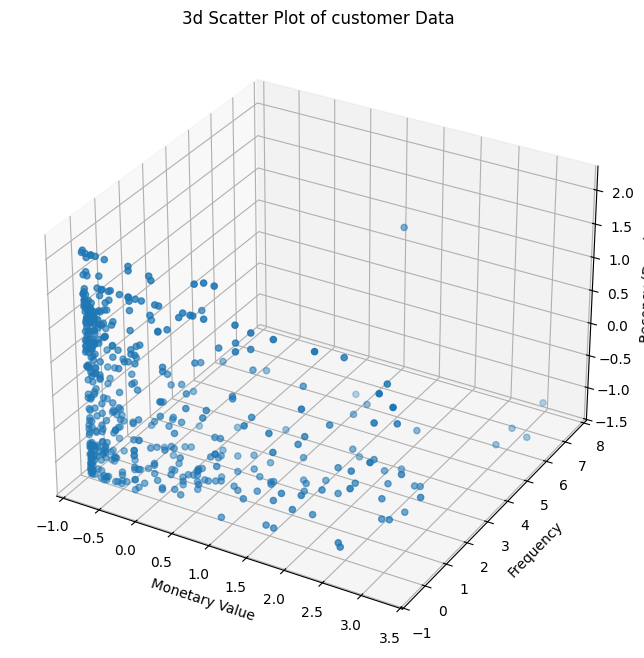

In [ ]:
fig=plt.figure(figsize=(8,8))
ax=fig.add_subplot(projection='3d')
scatter=ax.scatter(
    scaled_data_df['MonetaryValue'],
    scaled_data_df['Frequency'],
    scaled_data_df['Recency_Days'],
)
ax.set_xlabel('Monetary Value')
ax.set_ylabel('Frequency')
ax.set_zlabel('Recency (Days)')
ax.set_title('3d Scatter Plot of customer Data')
plt.show()

# K-Means Clustering

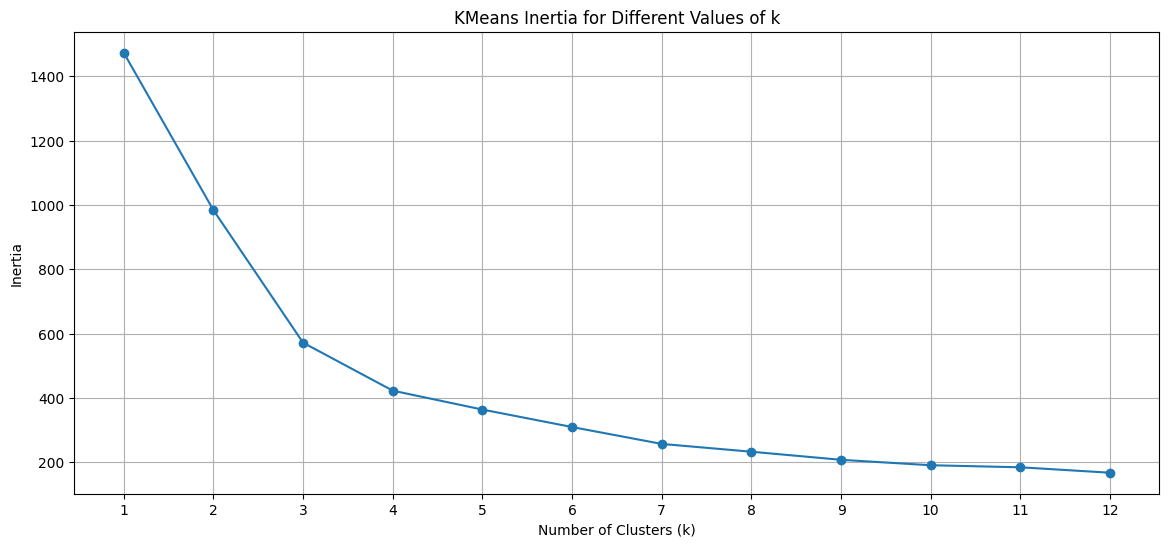

In [ ]:
max_k = 12
inertia = []
k_values = range(1, max_k + 1)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, max_iter=1000)
    kmeans.fit(scaled_data_df)
    inertia.append(kmeans.inertia_)

# Move plotting outside of the loop so inertia has all 12 values
plt.figure(figsize=(14, 6))
plt.plot(k_values, inertia, marker='o')
plt.title('KMeans Inertia for Different Values of k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid()
plt.show()

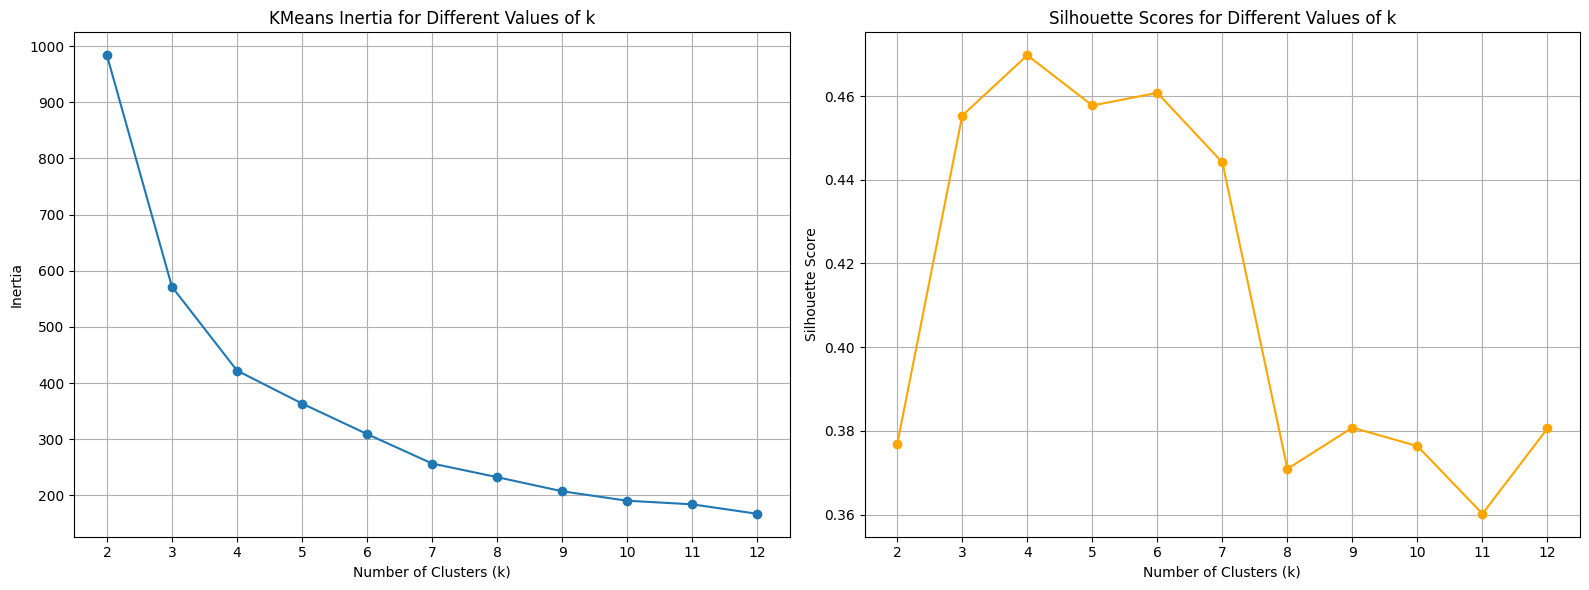

In [ ]:
max_k = 12
inertia = []
silhouette_scores = []
k_values = range(2, max_k + 1)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, max_iter=1000)
    cluster_labels = kmeans.fit_predict(scaled_data_df)
    sil_score = silhouette_score(scaled_data_df, cluster_labels)
    silhouette_scores.append(sil_score)
    inertia.append(kmeans.inertia_)

# Create a single figure with 2 subplots side-by-side
plt.figure(figsize=(16, 6))

# Left subplot: Inertia
plt.subplot(1, 2, 1)
plt.plot(k_values, inertia, marker='o')
plt.title('KMeans Inertia for Different Values of k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid(True)

# Right subplot: Silhouette Score
plt.subplot(1, 2, 2)
plt.plot(k_values, silhouette_scores, color='orange', marker='o')
plt.title('Silhouette Scores for Different Values of k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
kmeans=KMeans(n_clusters=4,random_state=42,max_iter=1000)
cluster_labels=kmeans.fit_predict(scaled_data_df)
cluster_labels

array([3, 1, 2, 2, 1, 0, 2, 2, 2, 2, 1, 1, 1, 2, 3, 1, 3, 0, 0, 2, 1, 1,
       1, 2, 1, 1, 1, 1, 0, 1, 1, 2, 2, 1, 0, 1, 2, 1, 1, 1, 0, 1, 0, 1,
       2, 2, 1, 1, 1, 0, 0, 0, 3, 2, 1, 2, 0, 2, 1, 3, 0, 3, 0, 0, 1, 1,
       2, 1, 0, 1, 1, 0, 2, 1, 0, 0, 1, 0, 2, 0, 2, 2, 0, 1, 2, 3, 3, 1,
       3, 0, 3, 3, 2, 1, 2, 1, 2, 2, 1, 0, 0, 1, 2, 0, 3, 1, 3, 1, 2, 3,
       0, 2, 1, 1, 0, 1, 0, 2, 0, 1, 2, 1, 2, 1, 0, 1, 0, 1, 2, 0, 2, 3,
       0, 3, 0, 3, 1, 2, 3, 2, 1, 2, 1, 1, 1, 2, 2, 2, 3, 1, 1, 3, 1, 0,
       1, 0, 1, 0, 2, 2, 0, 1, 1, 1, 1, 3, 0, 1, 0, 1, 1, 2, 3, 1, 3, 2,
       1, 1, 2, 1, 1, 1, 2, 0, 0, 1, 1, 2, 1, 0, 1, 0, 1, 0, 1, 2, 1, 0,
       0, 1, 0, 0, 0, 1, 0, 0, 2, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 2, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 0, 2, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0,
       0, 1, 0, 0, 0, 1, 3, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 3, 0,
       2, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,

In [ ]:
non_outliers_df['Cluster']=cluster_labels
non_outliers_df

/tmp/ipykernel_1790/98664061.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_outliers_df['Cluster']=cluster_labels


,Customer ID,MonetaryValue,Frequency,LastInvoiceData,Recency,Cluster
0,12346.00,203.50,9,2010-01-22 13:30:00,321 days 02:41:00,3
1,12348.00,1.00,1,2010-09-27 14:59:00,73 days 01:12:00,1
5,12358.00,200.00,1,2010-11-29 10:56:00,10 days 05:15:00,2
6,12360.00,280.00,3,2010-11-25 11:04:00,14 days 05:07:00,2
7,12361.00,45.00,3,2010-09-03 15:19:00,97 days 00:52:00,1
...,...,...,...,...,...,...
548,18257.00,15.00,1,2010-09-19 13:02:00,81 days 03:09:00,1
549,18284.00,50.00,1,2010-10-04 11:33:00,66 days 04:38:00,1
550,18285.00,50.00,1,2010-02-17 10:24:00,295 days 05:47:00,0
551,18286.00,50.00,1,2009-12-16 10:45:00,358 days 05:26:00,0


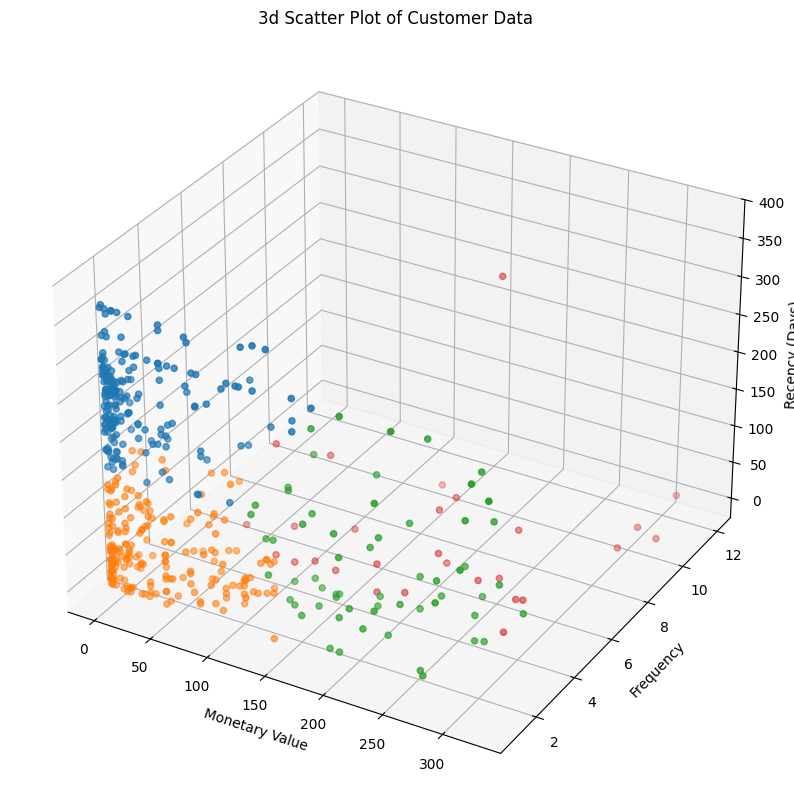

In [ ]:
cluster_colors = {0: '#1f77b4', 1: '#ff7f0e', 2: '#2ca02c', 3: '#d62728'}
colors = non_outliers_df['Cluster'].map(cluster_colors)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')

scatter = ax.scatter(
    non_outliers_df['MonetaryValue'],
    non_outliers_df['Frequency'],
    non_outliers_df['Recency'].dt.days,
    c=colors,
    marker='o'
)

ax.set_xlabel('Monetary Value')
ax.set_ylabel('Frequency')
ax.set_zlabel('Recency (Days)')
ax.set_title('3d Scatter Plot of Customer Data')
plt.show()

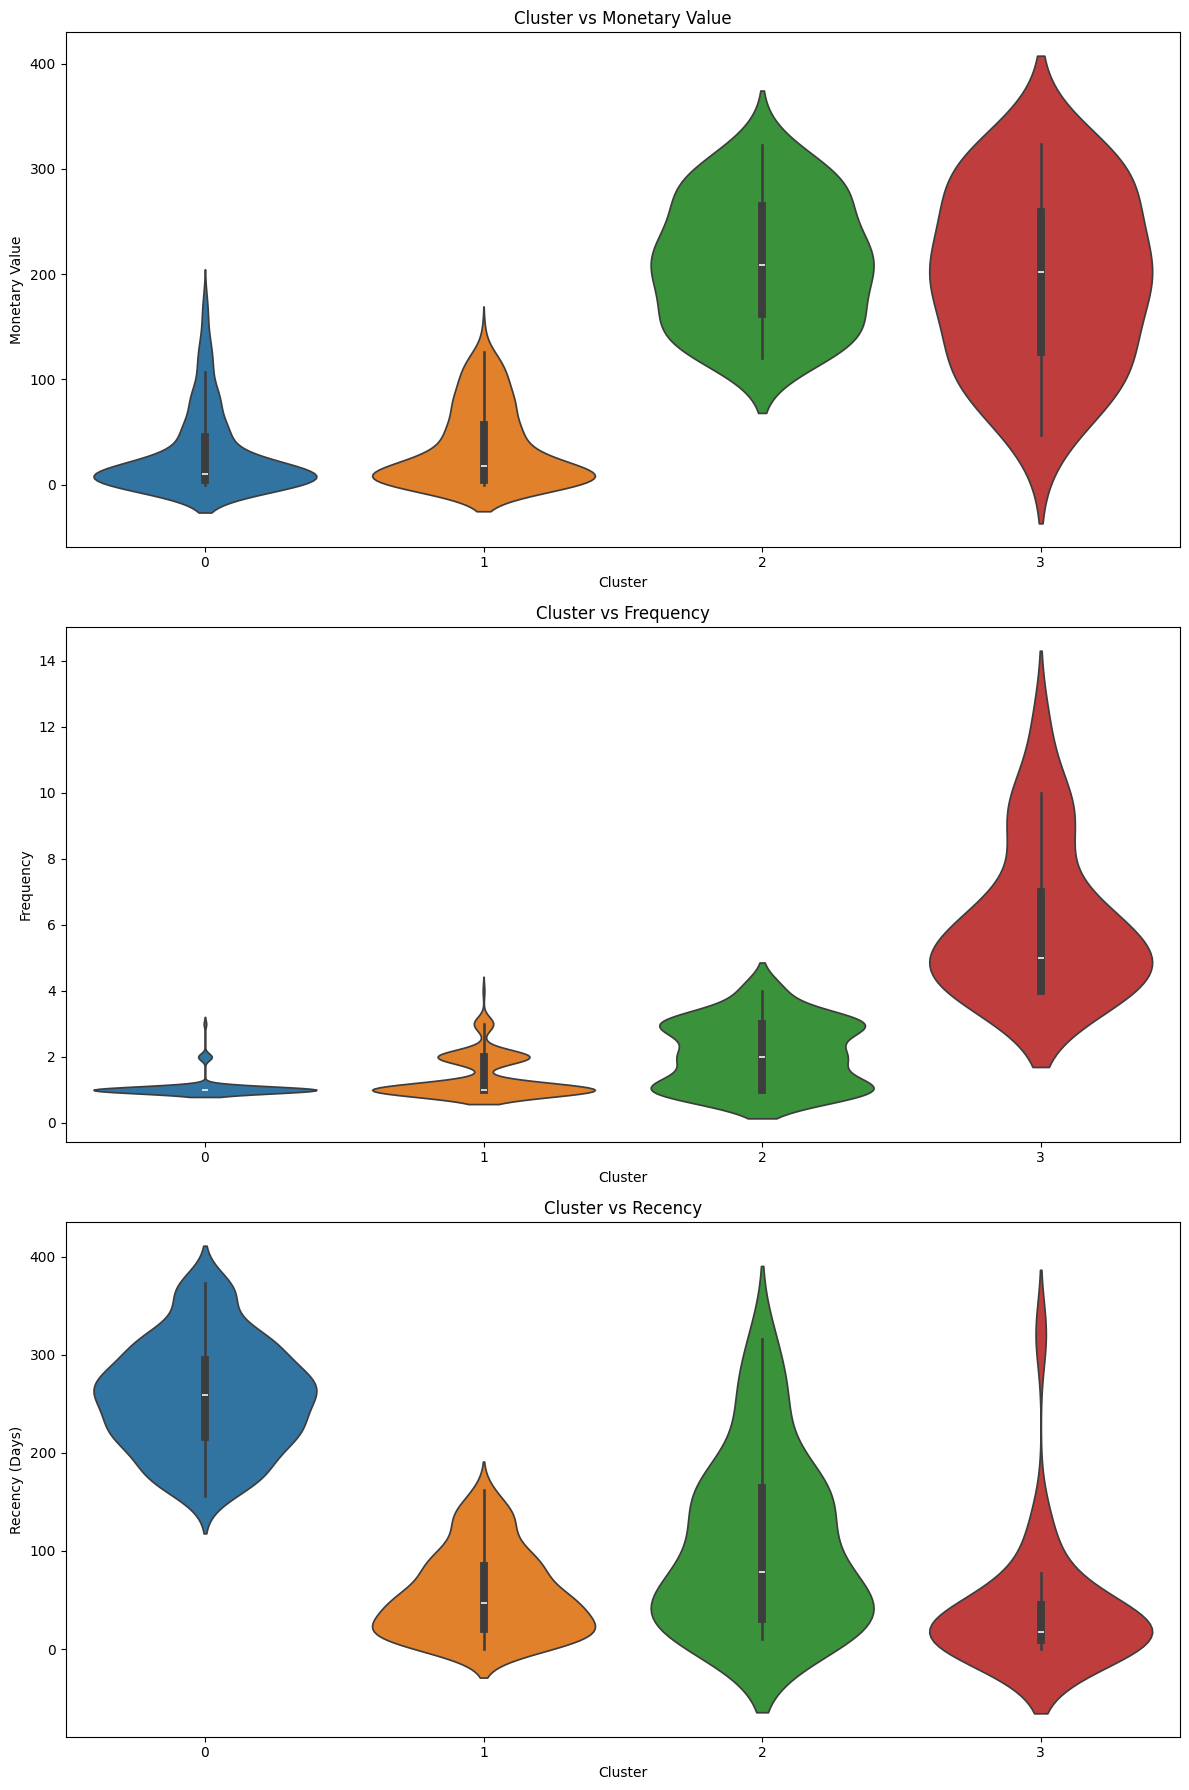

In [ ]:
plt.figure(figsize=(12, 18))

plt.subplot(3, 1, 1)
sns.violinplot(x=non_outliers_df['Cluster'], y=non_outliers_df['MonetaryValue'], palette=cluster_colors, hue=non_outliers_df['Cluster'], legend=False)
plt.title('Cluster vs Monetary Value')
plt.xlabel('Cluster')
plt.ylabel('Monetary Value')

plt.subplot(3, 1, 2)
sns.violinplot(x=non_outliers_df['Cluster'], y=non_outliers_df['Frequency'], palette=cluster_colors, hue=non_outliers_df['Cluster'], legend=False)
plt.title('Cluster vs Frequency')
plt.xlabel('Cluster')
plt.ylabel('Frequency')

plt.subplot(3, 1, 3)
sns.violinplot(x=non_outliers_df['Cluster'], y=non_outliers_df['Recency'].dt.days, palette=cluster_colors, hue=non_outliers_df['Cluster'], legend=False)
plt.title('Cluster vs Recency')
plt.xlabel('Cluster')
plt.ylabel('Recency (Days)')

plt.tight_layout()
plt.show()

In [ ]:
overlap_indices=monetary_outliers_df.index.intersection(frequency_outliers_df.index)
monetary_only_outliers=monetary_outliers_df.drop(overlap_indices)
monetary_only_outliers=frequency_outliers_df.drop(overlap_indices)
monetary_and_frequency_outliers=monetary_outliers_df.loc[overlap_indices]
monetary_outliers_df['Cluster']=-1
frequency_outliers_df['Cluster']=-1
monetary_only_outliers['Cluster']=-2
monetary_and_frequency_outliers['Cluster']=-3
outlier_clusters_df=pd.concat([monetary_outliers_df,frequency_outliers_df,monetary_only_outliers,monetary_and_frequency_outliers])
outlier_clusters_df

/tmp/ipykernel_1790/985641573.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  monetary_outliers_df['Cluster']=-1
/tmp/ipykernel_1790/985641573.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  frequency_outliers_df['Cluster']=-1


,Customer ID,MonetaryValue,Frequency,LastInvoiceData,Recency,Cluster
2,12349.00,450.00,2,2010-10-28 08:23:00,42 days 07:48:00,-1
3,12356.00,436.00,2,2010-11-11 14:23:00,28 days 01:48:00,-1
4,12357.00,850.00,1,2010-11-16 14:29:00,23 days 01:42:00,-1
11,12371.00,360.00,3,2010-10-26 13:37:00,44 days 02:34:00,-1
17,12380.00,2168.65,6,2010-08-31 14:54:00,100 days 01:17:00,-1
...,...,...,...,...,...,...
266,13520.00,600.00,6,2010-12-03 10:36:00,6 days 05:35:00,-3
284,13815.00,378.00,4,2010-10-29 11:42:00,41 days 04:29:00,-3
300,14156.00,9717.74,31,2010-11-21 12:38:00,18 days 03:33:00,-3
325,14646.00,783.00,14,2010-11-22 12:39:00,17 days 03:32:00,-3
